# How often does each model beat the baseline?

For each historical 48-hour window, a model gets **1 win if its RMSE is lower than seasonal naive**, otherwise 0.

**Win rate (%) = 100 × sum of window wins / number of windows.**

Example: 8 wins out of 11 windows = **72.7%**. This is the observed frequency on these windows, **not a probability of beating the hidden leaderboard**. A tiny win and a large win each count once, so we also show pooled RMSE reduction and the worst window.

This notebook compares the candidates available from the broad search, Hugging Face, ensemble, and Timestral experiments on the **same eleven selection windows**. Earlier ETS/ARIMA experiments used only five selection windows and are not included in this eleven-window ranking. The final, previously seen audit is separate. These windows have been reused for model selection, so results can be optimistic.

Weather stress pools three illustrative weather-error scenarios within each historical window. Each actual window still counts only once. Change `SCENARIO` to compare observed-weather results instead; those can be optimistic for weather models. No models are refitted by this notebook.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SCENARIO = "weather_stress"  # or "observed_weather"
source = next(Path(folder) for folder in ["results_timestral", "results_stacking", "results_hf"] if (Path(folder) / "window_comparison.csv").exists())
out = Path("results_win_rate")
out.mkdir(exist_ok=True)
windows = pd.read_csv(source / "window_comparison.csv", parse_dates=["start", "end"])
pooled = pd.read_csv(source / "model_comparison.csv")
selection = windows[(windows.scenario == SCENARIO) & (windows.phase == "selection")].copy()
assert not selection.duplicated(["model", "fold"]).any()
expected = set(selection[selection.model == "seasonal_naive"].fold)
assert len(expected) == 11
assert all(set(g.fold) == expected for _, g in selection.groupby("model"))

# Compare errors directly; treat numerically equal scores as ties.
selection["tie"] = np.isclose(selection.RMSE, selection.baseline_RMSE, rtol=1e-9, atol=1e-9)
selection["win"] = (selection.RMSE < selection.baseline_RMSE) & ~selection.tie
selection["loss"] = (selection.RMSE > selection.baseline_RMSE) & ~selection.tie
ranking = selection.groupby("model").agg(
    wins=("win", "sum"), ties=("tie", "sum"), losses=("loss", "sum"), windows=("fold", "nunique"),
    median_window_improvement_pct=("improvement_pct", "median"),
    worst_window_RMSE_ratio=("RMSE_ratio", "max"))
ranking["win_rate_pct"] = 100 * ranking.wins / ranking.windows
scores = pooled[(pooled.scenario == SCENARIO) & (pooled.phase == "selection")].set_index("model")
ranking["pooled_RMSE"] = scores.RMSE
ranking["pooled_RMSE_reduction_pct"] = 100 * (1 - scores.RMSE_ratio)
assert (ranking.wins + ranking.ties + ranking.losses == ranking.windows).all()
assert ranking.loc["seasonal_naive", "ties"] == 11
# Baseline ties itself; exclude it from the model win-rate ranking.
ranking = ranking.drop(index="seasonal_naive").sort_values(["win_rate_pct", "pooled_RMSE"], ascending=[False, True])
ranking = ranking[["wins", "ties", "losses", "windows", "win_rate_pct", "pooled_RMSE", "pooled_RMSE_reduction_pct", "median_window_improvement_pct", "worst_window_RMSE_ratio"]]
ranking.to_csv(out / f"win_rate_{SCENARIO}.csv")
print(f"Scenario: {SCENARIO}. Each model is compared on {len(expected)} identical windows.")
display(ranking.round(2))


Scenario: weather_stress. Each model is compared on 11 identical windows.


,wins,ties,losses,windows,win_rate_pct,pooled_RMSE,pooled_RMSE_reduction_pct,median_window_improvement_pct,worst_window_RMSE_ratio
model,,,,,,,,,
blend_equal50_timestral28_weather50,10,0,1,11,90.91,243.13,23.58,20.03,1.07
timestral_28m_weather_504h,9,0,2,11,81.82,240.79,24.31,23.91,1.18
equal_mean,9,0,2,11,81.82,265.86,16.43,12.27,1.20
median,9,0,2,11,81.82,271.78,14.57,13.09,1.28
timestral_5m_weather_504h,8,0,3,11,72.73,263.99,17.02,4.49,1.37
blend_SARIMA50_hour50,8,0,3,11,72.73,277.10,12.90,7.78,1.14
blend_SARIMA50_ridge50,8,0,3,11,72.73,282.33,11.26,9.88,1.16
blend_SARIMA50_correction50,8,0,3,11,72.73,291.36,8.42,3.70,1.07
residual_boosting_60d,8,0,3,11,72.73,298.74,6.10,4.82,1.21


## Percentage of windows won
Ranked by win rate, then pooled RMSE to break equal win rates. This ranking answers “how often?”, not “how much error overall?”.

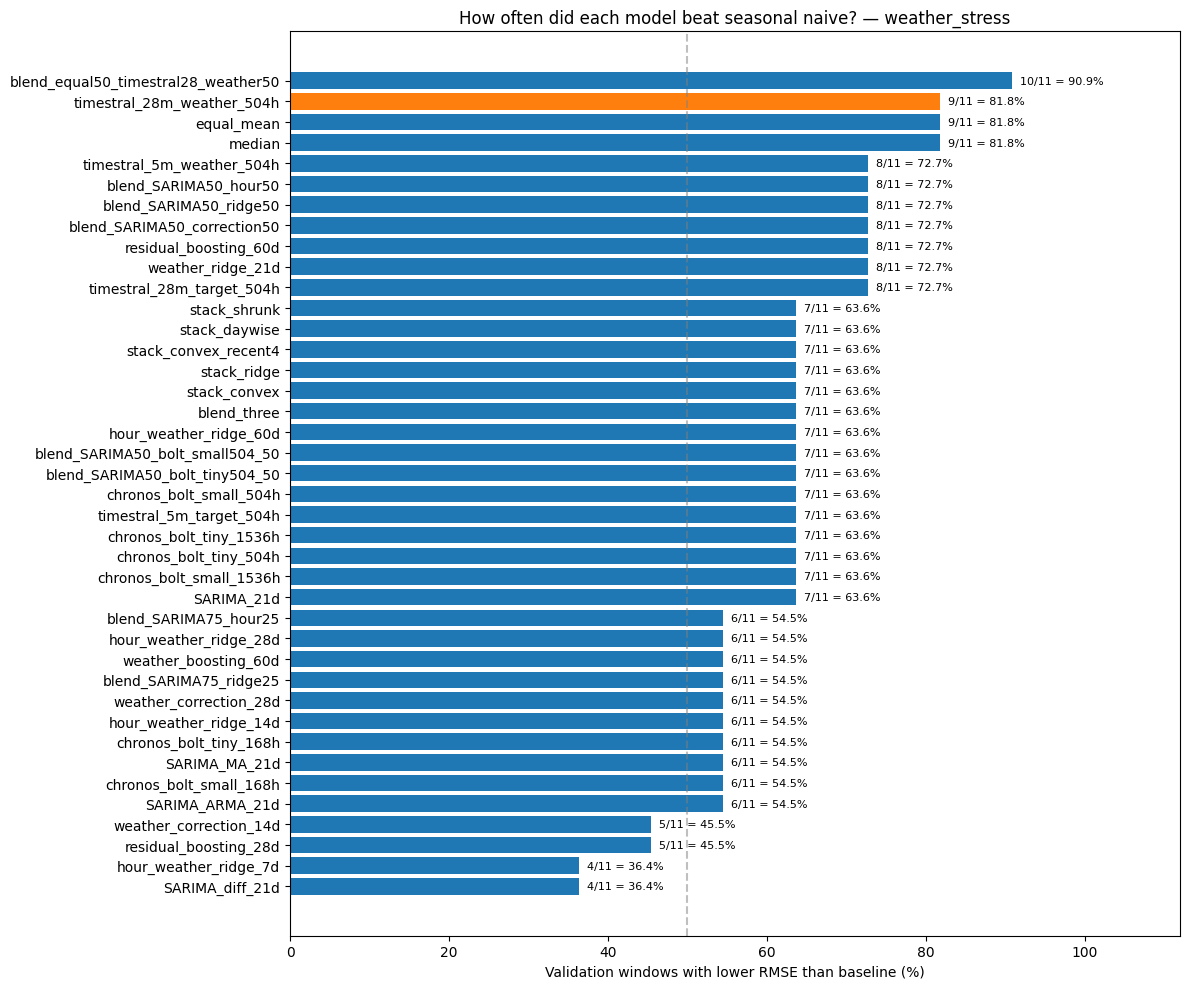

In [2]:
fig, ax = plt.subplots(figsize=(12, 10))
colors = ["tab:orange" if m == "timestral_28m_weather_504h" else "tab:blue" for m in ranking.index]
ax.barh(ranking.index, ranking.win_rate_pct, color=colors)
ax.invert_yaxis(); ax.set_xlim(0, 112)
for i, (_, row) in enumerate(ranking.iterrows()):
    ax.text(row.win_rate_pct + 1, i, f"{int(row.wins)}/{int(row.windows)} = {row.win_rate_pct:.1f}%", va="center", fontsize=8)
ax.set_xlabel("Validation windows with lower RMSE than baseline (%)")
ax.set_title(f"How often did each model beat seasonal naive? — {SCENARIO}")
ax.axvline(50, color="gray", linestyle="--", alpha=.5)
plt.tight_layout(); fig.savefig(out / f"win_rate_{SCENARIO}.png", dpi=160, bbox_inches="tight"); plt.show()


## Sum the wins yourself
Each green **1** is a win, red **−1** is a loss, and **0** is a tie. Counting the 1s across a row gives the model’s win count.

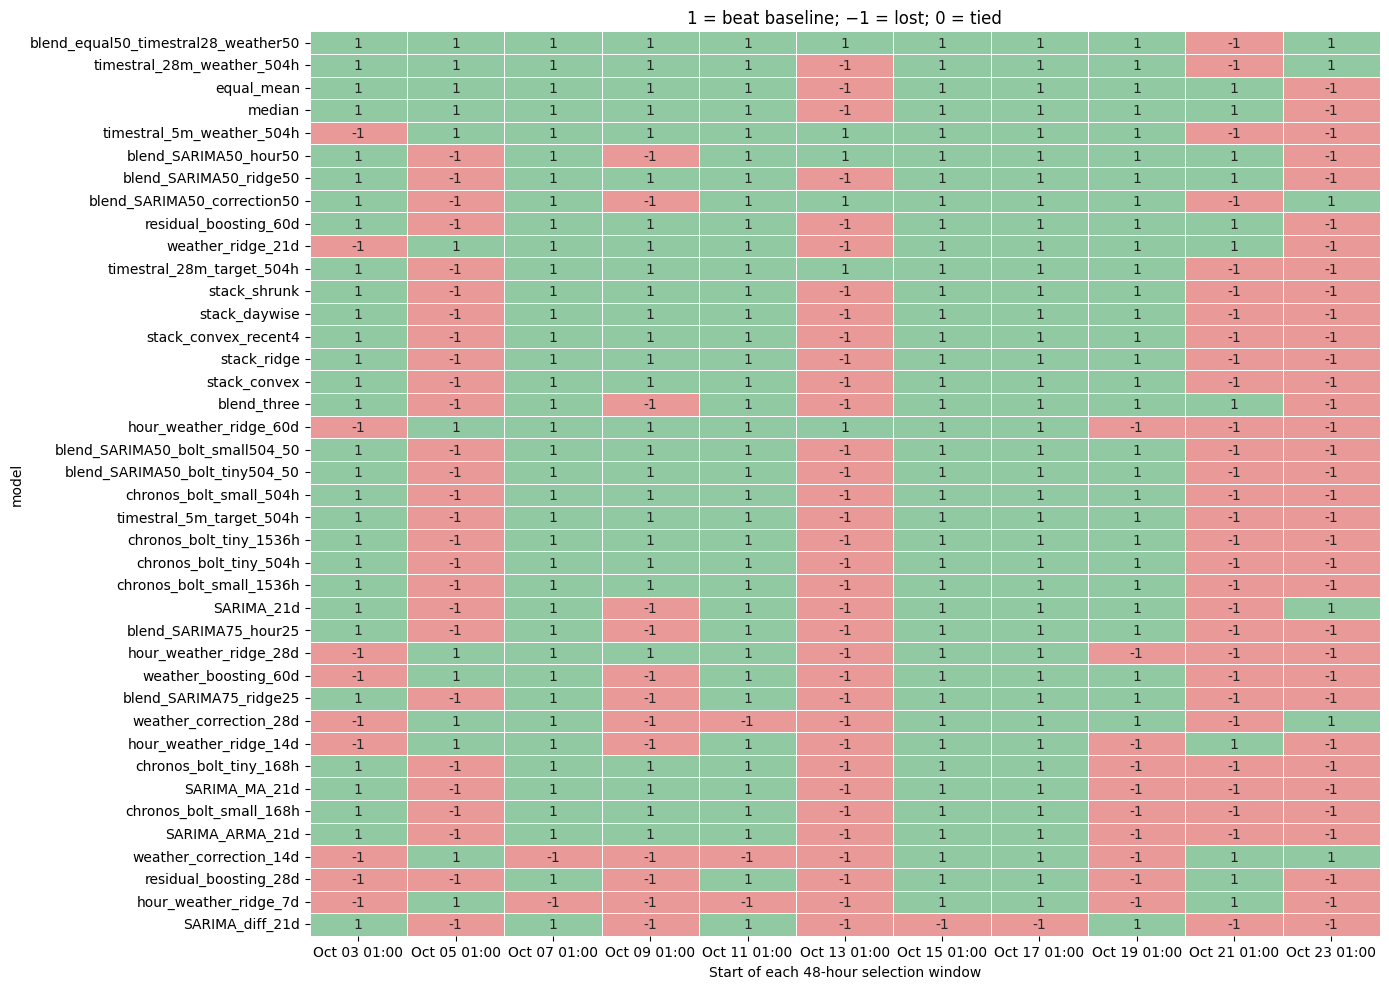

In [3]:
selection["outcome"] = selection.win.astype(int) - selection.loss.astype(int)
selection["label"] = selection.start.dt.strftime("%b %d %H:%M")
labels = selection.sort_values("start").label.drop_duplicates().tolist()
outcomes = selection.pivot(index="model", columns="label", values="outcome").reindex(index=ranking.index, columns=labels)
assert (outcomes.eq(1).sum(axis=1) == ranking.wins).all()
outcomes.to_csv(out / f"window_wins_{SCENARIO}.csv")
fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(outcomes, annot=True, fmt="d", cmap=sns.color_palette(["#e99a98", "#eeeeee", "#91c9a2"], as_cmap=True),
            vmin=-1, vmax=1, cbar=False, linewidths=.5, ax=ax)
ax.set_title("1 = beat baseline; −1 = lost; 0 = tied")
ax.set_xlabel("Start of each 48-hour selection window")
plt.tight_layout(); fig.savefig(out / f"window_wins_{SCENARIO}.png", dpi=160, bbox_inches="tight"); plt.show()


## Frequency of wins versus total error reduction
A model can win many windows by small amounts and lose a few by large amounts. Positive pooled RMSE reduction means lower total squared-error performance than baseline on these equal-length windows. Session 1 scoring uses RMSE on the hidden hours, not historical win count.

,wins,windows,win_rate_pct,pooled_RMSE_reduction_pct,worst_window_RMSE_ratio
model,,,,,
blend_equal50_timestral28_weather50,10,11,90.91,23.58,1.07
timestral_28m_weather_504h,9,11,81.82,24.31,1.18
equal_mean,9,11,81.82,16.43,1.20
blend_SARIMA50_hour50,8,11,72.73,12.90,1.14
SARIMA_21d,7,11,63.64,-0.76,1.26
weather_ridge_21d,8,11,72.73,3.47,1.54
blend_SARIMA50_bolt_small504_50,7,11,63.64,6.11,1.62


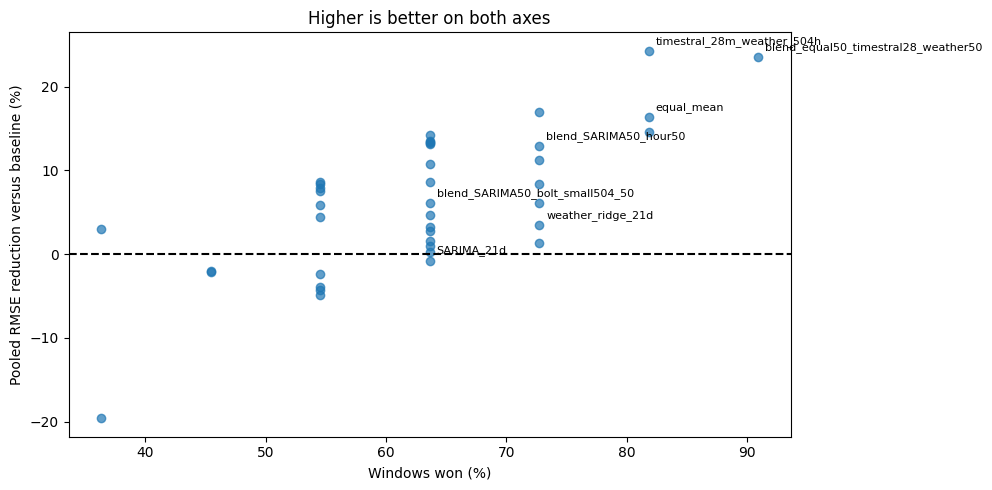

In [4]:
focus = list(dict.fromkeys([ranking.index[0], "timestral_28m_weather_504h", "equal_mean", "blend_SARIMA50_hour50", "SARIMA_21d", "weather_ridge_21d", "blend_SARIMA50_bolt_small504_50"]))
focus = [model for model in focus if model in ranking.index]
display(ranking.loc[focus, ["wins", "windows", "win_rate_pct", "pooled_RMSE_reduction_pct", "worst_window_RMSE_ratio"]].round(2))
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(ranking.win_rate_pct, ranking.pooled_RMSE_reduction_pct, alpha=.7)
for model in focus:
    row = ranking.loc[model]
    ax.annotate(model, (row.win_rate_pct, row.pooled_RMSE_reduction_pct), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.axhline(0, color="black", linestyle="--")
ax.set_xlabel("Windows won (%)"); ax.set_ylabel("Pooled RMSE reduction versus baseline (%)")
ax.set_title("Higher is better on both axes")
plt.tight_layout(); plt.show()


## Audit shown separately
This final window was already inspected previously. It is not included in the eleven-window win rate and is not an untouched test.

In [5]:
audit = windows[(windows.scenario == SCENARIO) & (windows.phase == "last_window_audit")].set_index("model")
audit["beats_baseline"] = (audit.RMSE < audit.baseline_RMSE) & ~np.isclose(audit.RMSE, audit.baseline_RMSE, rtol=1e-9, atol=1e-9)
display(audit.loc[focus + ["seasonal_naive"], ["start", "RMSE", "baseline_RMSE", "RMSE_ratio", "beats_baseline"]].round(3))
print("Win rate is descriptive evidence from history, not a guarantee for the hidden 48 hours.")


,start,RMSE,baseline_RMSE,RMSE_ratio,beats_baseline
model,,,,,
blend_equal50_timestral28_weather50,2026-10-25 01:00:00,164.562,120.404,1.367,False
timestral_28m_weather_504h,2026-10-25 01:00:00,180.137,120.404,1.496,False
equal_mean,2026-10-25 01:00:00,172.215,120.404,1.430,False
blend_SARIMA50_hour50,2026-10-25 01:00:00,162.473,120.404,1.349,False
SARIMA_21d,2026-10-25 01:00:00,116.108,120.404,0.964,True
weather_ridge_21d,2026-10-25 01:00:00,196.617,120.404,1.633,False
blend_SARIMA50_bolt_small504_50,2026-10-25 01:00:00,144.979,120.404,1.204,False
seasonal_naive,2026-10-25 01:00:00,120.404,120.404,1.000,False


Win rate is descriptive evidence from history, not a guarantee for the hidden 48 hours.
